<a href="https://colab.research.google.com/github/WinnieAmong/Applied_DataScience_Mary-Winnie_Project/blob/main/IMDB_Asssingment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install all required libraries.
# Run this once.
!pip install datasets scikit-learn pandas numpy matplotlib seaborn joblib transformers evaluate accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.2 MB/s eta 0:00:00


In [ ]:
# Import the Hugging Face datasets library.
from datasets import load_dataset

# Load the IMDB movie-review dataset.
ds = load_dataset("stanfordnlp/imdb")

# Print the available splits.
print(ds)

# Show one training example.
print(ds["train"][0])

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})
{'text': 'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and

In [ ]:
# Import pandas.
import pandas as pd

# Convert the official test split to pandas.
test_df = ds["test"].to_pandas()

# Keep the original test reviews and labels.
X_test_raw = test_df["text"]
y_test = test_df["label"]

# Print the test-set size and class balance.
print("Test examples:", len(X_test_raw))
print(y_test.value_counts())

Test examples: 25000
label
0    12500
1    12500
Name: count, dtype: int64


In [ ]:
# Import train_test_split.
from sklearn.model_selection import train_test_split

# Convert the training split to pandas.
train_df = ds["train"].to_pandas()

# Use the raw review text for TF-IDF.
X = train_df["text"]
y = train_df["label"]

# Split training data into:
# 90% training
# 10% validation
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.1,
    random_state=42,
    stratify=y
)

# Print the sizes.
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test_raw))

Training: 22500
Validation: 2500
Testing: 25000


In [ ]:
# Import TF-IDF, Logistic Regression, and Pipeline.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create a traditional NLP pipeline.
# TF-IDF converts text into numerical features.
# Logistic Regression learns to classify positive vs negative sentiment.
traditional_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,          # Convert text to lowercase.
        stop_words="english",    # Remove common words.
        ngram_range=(1, 2),      # Use words and two-word phrases.
        max_features=50000,      # Keep the most useful 50,000 features.
        min_df=2,                # Ignore very rare words.
        max_df=0.95,             # Ignore extremely common words.
        sublinear_tf=True        # Reduce the impact of repeated words.
    )),
    ("clf", LogisticRegression(
        C=1.0,                   # Regularization strength.
        solver="liblinear",      # Suitable solver for binary classification.
        max_iter=1000,           # Allow enough iterations to converge.
        class_weight="balanced", # Balance positive and negative classes.
        random_state=42
    ))
])

# Print the pipeline.
print(traditional_model)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_df=0.95, max_features=50000, min_df=2,
                                 ngram_range=(1, 2), stop_words='english',
                                 sublinear_tf=True)),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42, solver='liblinear'))])


In [ ]:
# Import time to measure training duration.
import time

# Record the start time.
start_time = time.time()

# Train TF-IDF and Logistic Regression.
traditional_model.fit(X_train, y_train)

# Record the end time.
traditional_train_time = time.time() - start_time

# Print training time.
print(f"Traditional model training time: {traditional_train_time:.2f} seconds")

In [ ]:
# Import evaluation metrics.
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict sentiment on the official test set.
traditional_preds = traditional_model.predict(X_test_raw)

# Calculate metrics.
traditional_accuracy = accuracy_score(y_test, traditional_preds)
traditional_precision = precision_score(y_test, traditional_preds)
traditional_recall = recall_score(y_test, traditional_preds)
traditional_f1 = f1_score(y_test, traditional_preds)

# Print the results.
print("Traditional NLP results: TF-IDF + Logistic Regression")
print(f"Accuracy:  {traditional_accuracy:.4f}")
print(f"Precision: {traditional_precision:.4f}")
print(f"Recall:    {traditional_recall:.4f}")
print(f"F1-score:  {traditional_f1:.4f}")

# Show the full classification report.
print("\nClassification report:")
print(classification_report(
    y_test,
    traditional_preds,
    target_names=["negative", "positive"]
))

# Show the confusion matrix.
print("Confusion matrix:")
print(confusion_matrix(y_test, traditional_preds))

Traditional NLP results: TF-IDF + Logistic Regression
Accuracy:  0.8866
Precision: 0.8838
Recall:    0.8902
F1-score:  0.8870

Classification report:
              precision    recall  f1-score   support

    negative       0.89      0.88      0.89     12500
    positive       0.88      0.89      0.89     12500

    accuracy                           0.89     25000
   macro avg       0.89      0.89      0.89     25000
weighted avg       0.89      0.89      0.89     25000

Confusion matrix:
[[11037  1463]
 [ 1373 11127]]


In [ ]:
# Import Hugging Face Transformer tools.
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Choose DistilBERT.
# It is a smaller, faster version of BERT.
model_name = "distilbert-base-uncased"

# Load the tokenizer.
# It converts text into tokens and token IDs.
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load the pretrained DistilBERT model.
# num_labels=2 because we have two sentiment classes.
bert_model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

# Print the label mapping.
print(bert_model.config.id2label)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{0: 'LABEL_0', 1: 'LABEL_1'}


In [ ]:
# Define a tokenization function.
def tokenize_function(example):
    return tokenizer(
        example["text"],
        truncation=True,       # Cut reviews that are too long.
        max_length=256         # Use at most 256 tokens.
    )

# Tokenize the training and test datasets.
tokenized_ds = ds.map(
    tokenize_function,
    batched=True
)

# Rename label to labels for Hugging Face Trainer.
tokenized_ds = tokenized_ds.rename_column("label", "labels")

# Remove the raw text column because the model uses token IDs.
tokenized_ds = tokenized_ds.remove_columns(["text"])

# Set the dataset format for PyTorch.
tokenized_ds.set_format("torch")

# Inspect the tokenized columns.
print(tokenized_ds["train"][0].keys())

In [ ]:
# Import evaluate and NumPy.
import evaluate
import numpy as np

# Load accuracy metric.
accuracy_metric = evaluate.load("accuracy")

# Define a function to compute metrics.
def compute_metrics(eval_pred):
    # Get model logits and true labels.
    logits, labels = eval_pred

    # Convert logits into predicted labels.
    predictions = np.argmax(logits, axis=-1)

    # Calculate accuracy.
    return accuracy_metric.compute(
        predictions=predictions,
        references=labels
    )

In [ ]:
# Import TrainingArguments.
from transformers import TrainingArguments

# Define the fine-tuning configuration.
training_args = TrainingArguments(
    output_dir="imdb_distilbert_model",  # Save checkpoints here.
    eval_strategy="epoch",               # Evaluate after each epoch.
    save_strategy="epoch",               # Save after each epoch.
    learning_rate=2e-5,                  # Small learning rate for fine-tuning.
    per_device_train_batch_size=16,      # Training batch size.
    per_device_eval_batch_size=32,       # Evaluation batch size.
    num_train_epochs=2,                  # Train for two epochs.
    weight_decay=0.01,                   # Regularization.
    load_best_model_at_end=True,         # Load the best checkpoint.
    metric_for_best_model="accuracy",    # Select best model by accuracy.
    logging_steps=100                    # Log progress every 100 steps.
)

In [ ]:
# Import Trainer and data collator.
from transformers import Trainer, DataCollatorWithPadding

# Create a data collator.
# It pads each batch dynamically.
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Create the Trainer.
bert_trainer = Trainer(
    model=bert_model,                         # Pretrained DistilBERT.
    args=training_args,                       # Training settings.
    train_dataset=tokenized_ds["train"],      # Training data.
    eval_dataset=tokenized_ds["test"],        # Test data.
    processing_class=tokenizer,               # Tokenizer.
    data_collator=data_collator,              # Dynamic padding.
    compute_metrics=compute_metrics           # Accuracy metric.
)

# Confirm the Trainer is ready.
print("BERT Trainer is ready.")

In [ ]:
# Import time.
import time

# Record the start time.
bert_start_time = time.time()

# Fine-tune the pretrained DistilBERT model.
bert_trainer.train()

# Record the end time.
bert_train_time = time.time() - bert_start_time

# Print training time.
print(f"BERT fine-tuning time: {bert_train_time:.2f} seconds")

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss


In [ ]:
# Evaluate the fine-tuned model.
bert_results = bert_trainer.evaluate()

# Print all evaluation metrics.
print(bert_results)

# Store BERT accuracy.
bert_accuracy = bert_results["eval_accuracy"]

In [ ]:
# Use the trained Trainer to predict on the test set.
bert_output = bert_trainer.predict(tokenized_ds["test"])

# Extract predicted labels.
bert_preds = np.argmax(bert_output.predictions, axis=-1)

# Calculate detailed metrics.
bert_precision = precision_score(y_test, bert_preds)
bert_recall = recall_score(y_test, bert_preds)
bert_f1 = f1_score(y_test, bert_preds)

# Print BERT results.
print("Modern NLP results: Fine-tuned DistilBERT")
print(f"Accuracy:  {bert_accuracy:.4f}")
print(f"Precision: {bert_precision:.4f}")
print(f"Recall:    {bert_recall:.4f}")
print(f"F1-score:  {bert_f1:.4f}")

# Show the classification report.
print("\nClassification report:")
print(classification_report(
    y_test,
    bert_preds,
    target_names=["negative", "positive"]
))

# Show the confusion matrix.
print("Confusion matrix:")
print(confusion_matrix(y_test, bert_preds))

In [ ]:
# Create a dictionary of results.
results = {
    "Model": [
        "TF-IDF + Logistic Regression",
        "Fine-tuned DistilBERT"
    ],
    "Accuracy": [
        traditional_accuracy,
        bert_accuracy
    ],
    "Precision": [
        traditional_precision,
        bert_precision
    ],
    "Recall": [
        traditional_recall,
        bert_recall
    ],
    "F1-score": [
        traditional_f1,
        bert_f1
    ],
    "Training time (seconds)": [
        traditional_train_time,
        bert_train_time
    ]
}

# Convert results into a DataFrame.
results_df = pd.DataFrame(results)

# Round numeric values for readability.
results_df[["Accuracy", "Precision", "Recall", "F1-score"]] = results_df[
    ["Accuracy", "Precision", "Recall", "F1-score"]
].round(4)

results_df["Training time (seconds)"] = results_df[
    "Training time (seconds)"
].round(2)

# Display the comparison table.
results_df

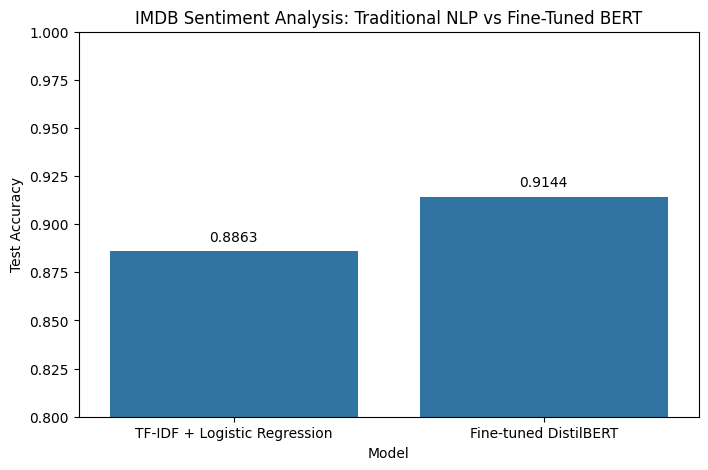

In [22]:
# Import plotting libraries.
import matplotlib.pyplot as plt
import seaborn as sns

# Create the plot.
plt.figure(figsize=(8, 5))

# Create a bar plot of accuracy.
sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

# Set plot title and labels.
plt.title("IMDB Sentiment Analysis: Traditional NLP vs Fine-Tuned BERT")
plt.ylim(0.80, 1.00)
plt.ylabel("Test Accuracy")
plt.xlabel("Model")

# Display accuracy values above bars.
for index, value in enumerate(results_df["Accuracy"]):
    plt.text(index, value + 0.005, f"{value:.4f}", ha="center")

# Show the plot.
plt.show()

In [26]:
# Import PyTorch.
import torch

# New movie reviews to classify.
reviews = [
    "This movie was absolutely amazing. The acting, story, and music were excellent.",
    "I hated this film. The plot was boring and the characters were awful.",
    "It was an average movie with a few good scenes but many slow moments."
]

# Find the device where the BERT model is located.
# This will usually be cuda:0 if you are using a GPU.
device = bert_model.device

print("Model device:", device)

# Tokenize the new reviews.
bert_inputs = tokenizer(
    reviews,
    return_tensors="pt",
    truncation=True,
    padding=True,
    max_length=256
)

# Move every input tensor to the same device as the model.
bert_inputs = {key: value.to(device) for key, value in bert_inputs.items()}

# Put the model in evaluation mode.
bert_model.eval()

# Predict without calculating gradients.
with torch.no_grad():
    bert_outputs = bert_model(**bert_inputs)

# Convert raw model outputs into probabilities.
bert_new_probs = torch.softmax(bert_outputs.logits, dim=-1)

# Choose the class with the highest probability.
bert_new_preds = torch.argmax(bert_new_probs, dim=-1)

# Display predictions.
for i, review in enumerate(reviews):
    bert_label = "Positive" if bert_new_preds[i].item() == 1 else "Negative"
    bert_confidence = bert_new_probs[i][bert_new_preds[i]].item()

    print("Review:", review)
    print("Fine-tuned BERT prediction:", bert_label)
    print("Confidence:", round(bert_confidence, 3))
    print("-" * 80)

Model device: cuda:0
Review: This movie was absolutely amazing. The acting, story, and music were excellent.
Fine-tuned BERT prediction: Positive
Confidence: 0.995
--------------------------------------------------------------------------------
Review: I hated this film. The plot was boring and the characters were awful.
Fine-tuned BERT prediction: Negative
Confidence: 0.996
--------------------------------------------------------------------------------
Review: It was an average movie with a few good scenes but many slow moments.
Fine-tuned BERT prediction: Negative
Confidence: 0.948
--------------------------------------------------------------------------------


In [27]:
# Import joblib.
import joblib

# Save the traditional model.
joblib.dump(traditional_model, "imdb_traditional_tfidf_logreg.joblib")

# Save the fine-tuned BERT model and tokenizer.
bert_trainer.save_model("imdb_fine_tuned_distilbert")
tokenizer.save_pretrained("imdb_fine_tuned_distilbert")

print("Both models saved successfully.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Both models saved successfully.


In [28]:
!pip install -q transformers datasets huggingface_hub gradio fastapi uvicorn pypdf sentence-transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 407.8/407.8 kB 8.2 MB/s eta 0:00:00


In [29]:
import os
from google.colab import userdata

HF_TOKEN = userdata.get("HF_TOKEN")      # read from Colab Secrets, never paste tokens in code
os.environ["HF_TOKEN"] = HF_TOKEN

from huggingface_hub import login, whoami
login(token=HF_TOKEN)
HF_USERNAME = whoami()["name"]
print("Logged in as:", HF_USERNAME)

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Logged in as: WinnieAmong


In [31]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

LOCAL_MODEL_DIR = "/content/imdb_fine_tuned_distilbert"  # TODO: path to your saved model

tokenizer = AutoTokenizer.from_pretrained(LOCAL_MODEL_DIR)
model = AutoModelForSequenceClassification.from_pretrained(LOCAL_MODEL_DIR)

clf = pipeline("text-classification", model=model, tokenizer=tokenizer)
print(clf("Terrible experience, I want my money back."))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'LABEL_0', 'score': 0.9877553582191467}]


In [35]:
MODEL_NAME = "groupMary_Winnie-sentiment-model"    # TODO: change to your model
MODEL_ID = f"{HF_USERNAME}/{MODEL_NAME}"

model.push_to_hub(MODEL_ID)
tokenizer.push_to_hub(MODEL_ID)
print("Model page:", f"https://huggingface.co/{MODEL_ID}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...yo24av7/model.safetensors:   6%|5         | 15.9MB /  268MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Model page: https://huggingface.co/WinnieAmong/groupMary_Winnie-sentiment-model


In [36]:
# Print the metrics that will appear in the model card.
print("Traditional accuracy:", traditional_accuracy)
print("Traditional F1:", traditional_f1)

print("BERT accuracy:", bert_accuracy)
print("BERT precision:", bert_precision)
print("BERT recall:", bert_recall)
print("BERT F1:", bert_f1)

Traditional accuracy: 0.88628
Traditional F1: 0.8866382232146417
BERT accuracy: 0.91444
BERT precision: 0.9059634824856986
BERT recall: 0.92488
BERT F1: 0.9153240172598076


In [42]:
from huggingface_hub import ModelCard

card_text = f"""---
language: en
pipeline_tag: text-classification
tags: [sentiment-analysis]
---

# {MODEL_NAME}
This model is a binary sentiment classifier for English movie reviews
It was fine-tuned from `distilbert-based-uncased` on the IMDB dataset

Sentiment classifier (positive / negative) fine-tuned from `distilbert-base-uncased`.


## Intended Use

This model is intended for sentiment analysis of English movie reviews.

**Group members:** TODO
-Mary Nabakka
-Winnie Among
**Dataset:** TODO (name of the Hugging Face dataset you used)
The model was fine-tuned on the [stanfordnlp/imdb](https://huggingface.co/datasets/stanfordnlp/imdb) dataset.



## Results on the test set
| Metric | Score |
|---|---|
| Accuracy | 0.91444  |
| F1    | 0.9153 |


## Example predictions
TODO: paste 3 examples
# Test the model with three example reviews.
examples = [
    "This movie was absolutely fantastic!",
    "Terrible experience, I want my money back.",
    "It was an average movie with a few good moments."
]

# Print predictions for the model card.
for review in examples:
    print(review)
    print(clf(review))

## Limitations
TODO: e.g. trained on English movie reviews only; struggles with sarcasm and Luganda/English mixed text.
- Trained mainly on English movie reviews.
- May struggle with sarcasm and mixed Luganda-English text.
- May not generalize well outside the movie-review domain.
"""

ModelCard(card_text).push_to_hub(MODEL_ID)
print("Model card uploaded.")

No files have been modified since last commit. Skipping to prevent empty commit.


Model card uploaded.


In [43]:
# Load the model card from the Hub to verify it was uploaded.
from huggingface_hub import ModelCard

# Load the README/model card from your repository.
uploaded_card = ModelCard.load(MODEL_ID)

# Print the beginning of the uploaded card.
print(str(uploaded_card)[:1000])

---
language: en
pipeline_tag: text-classification
tags:
- sentiment-analysis
---

# group1-sentiment-model
This model is a binary sentiment classifier for English movie reviews
It was fine-tuned from `distilbert-based-uncased` on the IMDB dataset

Sentiment classifier (positive / negative) fine-tuned from `distilbert-base-uncased`.


## Intended Use

This model is intended for sentiment analysis of English movie reviews.

**Group members:** TODO
-Mary Nabakka
-Winnie Among
**Dataset:** TODO (name of the Hugging Face dataset you used)
The model was fine-tuned on the [stanfordnlp/imdb](https://huggingface.co/datasets/stanfordnlp/imdb) dataset.



## Results on the test set
| Metric | Score |
|---|---|
| Accuracy | 0.91444  |
| F1    | 0.9153 |


## Example predictions
TODO: paste 3 examples
# Test the model with three example reviews.
examples = [
    "This movie was absolutely fantastic!",
    "Terrible experience, I want my money back.",
    "It was an average movie with a few good mo

In [44]:
hub_clf = pipeline("text-classification", model=MODEL_ID)
hub_clf("I really enjoyed this class!")

config.json:   0%|          | 0.00/642 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

[{'label': 'LABEL_1', 'score': 0.9942967295646667}]

In [45]:
import gradio as gr

def predict(text):
    if not text.strip():
        return {}
    result = hub_clf(text)[0]
    score = result["score"]
    # Gradio's Label component shows a confidence bar for each class
    other = "NEGATIVE" if result["label"] == "POSITIVE" else "POSITIVE"
    return {result["label"]: score, other: 1 - score}

demo = gr.Interface(
    fn=predict,
    inputs=gr.Textbox(lines=3, placeholder="Type a sentence..."),
    outputs=gr.Label(num_top_classes=2),
    title="Sentiment Analyser",
    description="Type a sentence and see if it is positive or negative.",
    examples=["The food was amazing!", "Worst service ever.", "It was okay, nothing special."],
)
demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f2a5cf13a6d26dc09d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [46]:
import gradio as gr
from transformers import pipeline

MODEL_ID = "WinnieAmong/groupMary_Winnie-sentiment-model"   # TODO: your model id
clf = pipeline("text-classification", model=MODEL_ID)

def predict(text):
    if not text.strip():
        return {}
    r = clf(text)[0]
    other = "NEGATIVE" if r["label"] == "POSITIVE" else "POSITIVE"
    return {r["label"]: r["score"], other: 1 - r["score"]}

demo = gr.Interface(
    fn=predict,
    inputs=gr.Textbox(lines=3, placeholder="Type a sentence..."),
    outputs=gr.Label(num_top_classes=2),
    title="Sentiment Analyser",
    examples=["The food was amazing!", "Worst service ever."],
)
demo.launch()

config.json:   0%|          | 0.00/642 [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6bfdad699d6e86f5c3.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [47]:
%%writefile requirements.txt
transformers
torch

Writing requirements.txt


In [ ]:
from huggingface_hub import HfApi
api = HfApi()

# Replace the placeholder model id inside app.py with yours
app_code = open("app.py").read().replace("WinnieAmong/groupMary_Winnie-sentiment-model", MODEL_ID)
open("app.py", "w").write(app_code)

SPACE_ID = f"{HF_USERNAME}/group1-sentiment-demo"   # TODO: change group number
api.create_repo(SPACE_ID, repo_type="space", space_sdk="gradio", exist_ok=True)
api.upload_file(path_or_fileobj="app.py", path_in_repo="app.py", repo_id=SPACE_ID, repo_type="space")
api.upload_file(path_or_fileobj="requirements.txt", path_in_repo="requirements.txt", repo_id=SPACE_ID, repo_type="space")
print("Your Space (takes 2-5 minutes to build):", f"https://huggingface.co/spaces/{SPACE_ID}")